# Sistema de Gating Front-End (Roteamento Dinâmico de Entradas) – Dataset IARA
### Notebook 24: Arquitetura Multimodal Agnóstica ao Modelo Classificador com Suporte a 4 Representações

Neste notebook, investigamos a arquitetura de **Gating Front-End (Multiplexador Dinâmico de Entradas)** no problema de reconhecimento de alvos acústicos submarinos passivos (*Underwater Acoustic Target Recognition* - UATR) sobre o dataset **IARA** (*Silva et al.*, IEEE Access 2025).

### Princípios da Arquitetura de Roteamento e Protocolo:
1. **O Foco é o Processo de Roteamento da Entrada:** O roteador avalia **7 meta-características físicas** extraídas dos primeiros $10\text{ s}$ do sinal acústico bruto e seleciona a representação espectral (**MEL**, **LOFAR**, **HHT** ou **DEMON**) cuja predição será usada.
2. **Modelo Downstream Agnóstico e Modular:** O classificador final não é fixo. A arquitetura aceita qualquer família de modelo (Random Forest, MLP, SVM Nyström ou CNN 2D) ou combinações heterogêneas (**H-MoE**).
3. **Especialistas já treinados:** cada ramo usa as predições por arquivo de um modelo treinado em uma única representação (Seção 3.1 lista a procedência de cada um). Os especialistas **não são homogêneos dentro da mesma família** (pipelines, hiperparâmetros e resoluções diferentes).
4. **Protocolo $5\times2\text{cv}$ (*Silva et al.*, 2025) e Prevenção de Vazamento Inter-Repetição (`trn_fold = fold ^ 1`):**
   * O particionamento oficial $5\times2\text{cv}$ (5 repetições de *2-fold CV*) é feito por **gravação de áudio (`ID`)**, não por navio (`Ship ID`): o mesmo navio pode aparecer em gravações de treino e de teste. O conjunto UO tem **1.706 gravações**; cada fold de teste tem **639 gravações**, e os dois folds de teste de uma repetição somam 1.278 gravações (639 × 2); as outras 428 gravações não entram no teste daquela repetição. Somando os 10 folds são 6.390 avaliações, ou seja, cada gravação aparece em média 3,75 vezes num conjunto de teste.
   * Para um fold de teste $k$, os 8 folds das **outras 4 repetições** contêm em média $99,6\%$ dos arquivos de teste de $k$. Treinar o roteador nos "outros 9 folds" faria o roteador memorizar as 7 meta-features de cada `file_id`.
   * Por isso o roteador e a seleção de modelos (*Nested CV*) são treinados **exclusivamente no fold complementar da mesma repetição (`trn_fold = fold ^ 1`)**, com **0% de sobreposição de arquivos** (`assert` no código).

In [1]:
import os
import sys
import pickle
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display, HTML
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R   # métricas dos experimentos isolados a partir dos CSVs por janela
import gating_comum as G   # réplica do roteador (SP por fold), oráculos e F-test

# Configuração de estilo visual (sem dependência do seaborn)
if 'seaborn-v0_8-whitegrid' in plt.style.available:
    plt.style.use('seaborn-v0_8-whitegrid')
elif 'seaborn-whitegrid' in plt.style.available:
    plt.style.use('seaborn-whitegrid')
else:
    plt.style.use('default')

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 15,
    'figure.dpi': 120
})

print("Ambiente configurado com sucesso para visualização científica (sem dependência de seaborn).")

Ambiente configurado com sucesso para visualização científica (sem dependência de seaborn).


## 1. Arquitetura do Sistema Gating Front-End

Abaixo apresentamos o fluxo de processamento do sistema. O módulo `Acoustic Front-End Gating` atua como um multiplexador dinâmico na entrada, roteando o áudio entre as 4 representações a partir de 7 descritores extraídos dos primeiros $10\text{ s}$ do áudio:

```
                            Sinal de Áudio Submarino (.wav, janela 10s)
                                           │
                                           ▼
                     ┌───────────────────────────────────────────┐
                     │    Acoustic Front-End Gating (Router)     │
                     │  7 Meta-features físicas (janela 10s):    │
                     │  • High / Low Energy Ratio & RMS (dB)     │
                     │  • Crest Factor (< 250 Hz) & ZCR          │
                     │  • Spectral Flatness & Spectral Flux      │
                     │  • Modulation Index (2 - 8 kHz)           │
                     └─────────────────────┬─────────────────────┘
                                           │
                                           │ Seleção Dinâmica da Entrada
                                           ▼
               ┌───────────────┬───────────────────┬───────────────┐
               ▼               ▼                   ▼               ▼
        [    MEL    ]   [   LOFAR    ]      [    HHT    ]   [   DEMON   ]
        (Banda Larga /  (Raias Tonais /     (Freq. Instant. (Modulação /
         Ruído Geral)    Diesel Lento)       / Transitórios) Cavitação)
               │               │                   │               │
               └───────────────┼───────────────────┼───────────────┘
                               │
                               ▼
            ┌─────────────────────────────────────────────┐
            │       Classificador Downstream Modular      │
            │   (Homogêneo: RF, MLP, SVM, CNN ou H-MoE)   │
            └──────────────────────┬──────────────────────┘
                                   │
                                   ▼
                        Predição Final da Classe
                 [Small | Medium | Large | Background]
```

### Motivação física de cada ramo (hipóteses de projeto, não testadas aqui):
* **`MEL`:** banco de filtros psicoacústico de banda larga; representação genérica de ruído hidrodinâmico contínuo.
* **`LOFAR`:** análise de banda estreita em baixa frequência; pensada para raias harmônicas tonais de máquinas.
* **`HHT`:** Transformada de Hilbert-Huang via Decomposição em Modos Empíricos (EMD); frequências instantâneas de eventos não-estacionários.
* **`DEMON`:** demodulação de envoltória na banda de cavitação; frequência de rotação do eixo e de passagem de pás.

## 1.1 Metodologia do Protocolo 5x2cv: Por que os Áudios se Repetem e a Solução `trn_fold = fold ^ 1`

### A Diferença Fundamental entre 10-fold CV Comum e o 5x2cv:
* **No 10-fold CV tradicional:** O dataset é dividido em 10 fatias disjuntas ($10\%$ cada). Cada áudio é avaliado no conjunto de teste exatamente **1 vez** na vida.
* **No 5x2cv (5 Repetições de 2-Fold CV - Dietterich, 1998 / Silva et al., 2025):** O dataset é dividido meio a meio ($50\%$ treino e $50\%$ teste) e esse processo é repetido **5 vezes independentes**, reembaralhando os mesmos áudios com sementes diferentes a cada repetição.

Como em **cada uma das 5 repetições** todos os áudios da base são avaliados (metade no fold par, metade no fold ímpar), **cada áudio é testado de 3 a 5 vezes ao longo dos 10 folds**!

---

### Exemplo Didático: Acompanhando um Áudio através das 5 Repetições
Imagine um dataset simples com 4 gravações: `[A, B, C, D]`. Veja como os mesmos arquivos são distribuídos:

1. **Repetição 1 (Semente 1):**
   * **Fold 0 (Teste):** `[A, B]` (Treino é `[C, D]`)
   * **Fold 1 (Teste):** `[C, D]` (Treino é `[A, B]`)
   * *O áudio A foi testado no Fold 0.*
2. **Repetição 2 (Semente 2 - Reembaralha os mesmos 4 áudios):**
   * **Fold 2 (Teste):** `[A, C]` (Treino é `[B, D]`)
   * **Fold 3 (Teste):** `[B, D]` (Treino é `[A, C]`)
   * *O áudio A agora foi testado no Fold 2!*
3. **Repetição 3 (Semente 3):**
   * **Fold 4 (Teste):** `[A, D]` | **Fold 5 (Teste):** `[B, C]` *(Áudio A testado no Fold 4)*
4. **Repetição 4 (Semente 4):**
   * **Fold 6 (Teste):** `[B, A]` | **Fold 7 (Teste):** `[C, D]` *(Áudio A testado no Fold 6)*
5. **Repetição 5 (Semente 5):**
   * **Fold 8 (Teste):** `[C, A]` | **Fold 9 (Teste):** `[D, B]` *(Áudio A testado no Fold 8)*

> **Conclusão:** O áudio `A` apareceu no teste de **5 folds diferentes** (`Fold 0, 2, 4, 6 e 8`).

---

### O Desastre do Vazamento de Dados no Código Antigo:
No código anterior do notebook, o loop de treino do roteador fazia:
```python
# CÓDIGO ANTIGO (COM VAZAMENTO MASSIVO DE 99,6%):
for fold in range(10):
    for trn_fold in range(10):
        if trn_fold == fold:
            continue  # "pular apenas o próprio fold de teste"
        # Treinar roteador em trn_fold...
```
**O que acontecia:** Ao avaliar o `Fold 0`, o roteador era treinado com os Folds `1, 2, 3, 4, 5, 6, 7, 8 e 9`. Mas os Folds 2, 4, 6 e 8 continham o áudio `A`! O roteador recebia o áudio `A` **4 vezes no treino**, decorando seu vetor estático de 7 meta-features e o gabarito de acerto dos especialistas. Isso inflava o SP artificialmente para quase $70\%$.

---

### A Solução Matemática: `trn_fold = fold ^ 1` (Bitwise XOR)
O operador `^` em Python inverte o bit menos significativo (LSB), mapeando cada fold exclusivamente para o seu **parceiro complementar na mesma repetição**:

| Fold de Teste (`fold`) | Operação Bitwise | Fold de Treino Disjunto (`trn_fold = fold ^ 1`) | Repetição | Sobreposição de Áudios |
| :---: | :---: | :---: | :---: | :---: |
| **Fold 0** | `0 ^ 1` | **Fold 1** | Repetição 1 | **0% (Disjunção Estrita)** |
| **Fold 1** | `1 ^ 1` | **Fold 0** | Repetição 1 | **0% (Disjunção Estrita)** |
| **Fold 2** | `2 ^ 1` | **Fold 3** | Repetição 2 | **0% (Disjunção Estrita)** |
| **Fold 3** | `3 ^ 1` | **Fold 2** | Repetição 2 | **0% (Disjunção Estrita)** |
| **Fold 4** | `4 ^ 1` | **Fold 5** | Repetição 3 | **0% (Disjunção Estrita)** |
| **Fold 5** | `5 ^ 1` | **Fold 4** | Repetição 3 | **0% (Disjunção Estrita)** |
| **Fold 6** | `6 ^ 1` | **Fold 7** | Repetição 4 | **0% (Disjunção Estrita)** |
| **Fold 7** | `7 ^ 1` | **Fold 6** | Repetição 4 | **0% (Disjunção Estrita)** |
| **Fold 8** | `8 ^ 1` | **Fold 9** | Repetição 5 | **0% (Disjunção Estrita)** |
| **Fold 9** | `9 ^ 1` | **Fold 8** | Repetição 5 | **0% (Disjunção Estrita)** |

A célula de código a seguir executa uma verificação empírica sobre os 10 folds do IARA, provando numericamente o isolamento estrito.

In [2]:
# Verificação Empírica da Disjunção do Protocolo 5x2cv no Dataset IARA
import pickle
import pandas as pd

# Carregar as predições e fids de teste salvos
import os
_pkl = 'data/iara_processed/rf_all_representations_predictions.pkl'
if not os.path.exists(_pkl):
    _pkl = os.path.join('..', _pkl)  # executado a partir de notebooks/
with open(_pkl, 'rb') as f:
    pred_data = pickle.load(f)

test_fids = {fold: set(pred_data['targets'][fold].keys()) for fold in range(10)}

audit_rows = []
for fold in range(10):
    par_fold = fold ^ 1
    # 1. Sobreposição com o parceiro complementar da mesma repetição (trn_fold = fold ^ 1)
    overlap_partner = len(test_fids[fold].intersection(test_fids[par_fold]))
    
    # 2. Sobreposição com os outros 8 folds das outras repetições (trn_fold != fold e != par_fold)
    other_folds_fids = set.union(*[test_fids[f] for f in range(10) if f not in (fold, par_fold)])
    overlap_others = len(test_fids[fold].intersection(other_folds_fids))
    pct_leakage = (overlap_others / len(test_fids[fold])) * 100
    
    # Validação formal
    assert overlap_partner == 0, f"Vazamento detectado entre fold {fold} e {par_fold}!"
    
    audit_rows.append({
        'Fold Avaliado': f'Fold {fold}',
        'Tamanho do Teste': len(test_fids[fold]),
        'Parceiro (trn_fold = fold ^ 1)': f'Fold {par_fold}',
        'Sobreposição c/ Parceiro': f'{overlap_partner} áudios (0.0%) [SEGURO]',
        'Vazamento se treinasse nos outros folds': f'{overlap_others} áudios ({pct_leakage:.1f}%) [LEAKAGE]'
    })

df_audit = pd.DataFrame(audit_rows)
print("=" * 110)
print("AUDITORIA EMPÍRICA DE DISJUNÇÃO: trn_fold = fold ^ 1 vs. trn_fold != fold")
print("=" * 110)
print(df_audit.to_string(index=False))
print("-" * 110)
print("CONCLUSÃO: O uso de 'trn_fold = fold ^ 1' garante exatamente 0% de sobreposição em todos os 10 folds!")

AUDITORIA EMPÍRICA DE DISJUNÇÃO: trn_fold = fold ^ 1 vs. trn_fold != fold
Fold Avaliado  Tamanho do Teste Parceiro (trn_fold = fold ^ 1) Sobreposição c/ Parceiro Vazamento se treinasse nos outros folds
       Fold 0               639                         Fold 1 0 áudios (0.0%) [SEGURO]            637 áudios (99.7%) [LEAKAGE]
       Fold 1               639                         Fold 0 0 áudios (0.0%) [SEGURO]            634 áudios (99.2%) [LEAKAGE]
       Fold 2               639                         Fold 3 0 áudios (0.0%) [SEGURO]            635 áudios (99.4%) [LEAKAGE]
       Fold 3               639                         Fold 2 0 áudios (0.0%) [SEGURO]           639 áudios (100.0%) [LEAKAGE]
       Fold 4               639                         Fold 5 0 áudios (0.0%) [SEGURO]            637 áudios (99.7%) [LEAKAGE]
       Fold 5               639                         Fold 4 0 áudios (0.0%) [SEGURO]            634 áudios (99.2%) [LEAKAGE]
       Fold 6               63

## 2. Análise Estatística das Meta-Características Acústicas Físicas

Carregamos as 7 meta-características físicas extraídas dos primeiros $10\text{ s}$ de cada um dos $1.825$ arquivos de áudio do IARA (`cache_gating_metafeatures.pkl`, todos os subconjuntos; os experimentos usam só as 1.706 gravações do UO) e inspecionamos sua distribuição.

In [3]:
# Carregar meta-características acústicas físicas (janela de 10s por gravação)
meta_paths = [
    'data/iara_processed/cache_gating_metafeatures.pkl',
    '../data/iara_processed/cache_gating_metafeatures.pkl'
]
meta_path = next((p for p in meta_paths if os.path.exists(p)), None)

if meta_path is None:
    raise FileNotFoundError("Arquivo cache_gating_metafeatures.pkl não encontrado.")

with open(meta_path, 'rb') as f:
    meta_dict = pickle.load(f)

df_meta = pd.DataFrame.from_dict(meta_dict, orient='index')
df_meta.index.name = 'file_id'
df_meta.reset_index(inplace=True)

print(f"Total de áudios com meta-características físicas extraídas (janela 10s): {len(df_meta)}")
df_meta[['crest_factor', 'spectral_flatness', 'mod_index', 'flux_std', 'high_low_ratio', 'rms_db', 'zcr']].describe().round(3)

Total de áudios com meta-características físicas extraídas (janela 10s): 1825


,crest_factor,spectral_flatness,mod_index,flux_std,high_low_ratio,rms_db,zcr
count,1825.000,1825.000,1825.000,1825.000,1825.000,1825.000,1825.000
mean,4.888,0.471,1.137,0.277,1.044,-41.732,0.086
std,2.635,0.236,0.288,0.270,5.767,10.622,0.075
min,0.074,0.006,0.013,0.003,0.000,-91.656,0.000
25%,3.024,0.281,1.056,0.116,0.031,-45.857,0.033
50%,4.256,0.486,1.106,0.196,0.126,-41.195,0.065
75%,6.001,0.661,1.223,0.343,0.473,-35.725,0.113
max,18.591,1.000,2.301,2.941,158.019,-12.733,0.425


## 3. Desempenho Experimental Comparativo Livre de Vazamento (10 Folds $5\times2\text{cv}$, `trn_fold = fold ^ 1`)

Avaliamos o **RF Competence Router** (`n_estimators=50, max_depth=3, min_samples_leaf=5`, escore = 0,9 × probabilidade de acerto + 0,1 × SP do especialista no fold de treino; treinado exclusivamente no fold disjunto `trn_fold = fold ^ 1`) atuando como multiplexador de entrada nas 4 famílias de classificadores:
1. **Random Forest (RF)**
2. **Multi-Layer Perceptron (MLP)**
3. **Support Vector Machine (SVM Nyström RBF)**
4. **CNN 2D**

> **Atenção — escolha dos hiperparâmetros do roteador.** Esta configuração (`max_depth=3`, `min_samples_leaf=5`, peso do prior 0,1) não foi escolhida num conjunto de validação próprio: ela é a melhor ou quase a melhor de 18 variantes **avaliadas no próprio teste** (Seção 3.2). Os resultados abaixo são, portanto, otimistas.

Em cada família comparamos:
* as **4 entradas isoladas** (sem roteamento), destacando a **melhor entrada isolada** da família;
* o **Gated Model** (roteamento via meta-features treinado apenas em `fold ^ 1`), com o **F-test 5×2cv** (Alpaydin, o mesmo teste do artigo) contra a melhor entrada isolada;
* o **Oráculo** (acerta se *alguma* das 4 entradas acertar). O oráculo usa o rótulo verdadeiro para escolher a entrada: **não é um sistema realizável**. Mostramos também o SP esperado se os erros das 4 entradas fossem independentes.

### 3.1 Procedência dos 16 especialistas

As predições por arquivo usadas pelo gate (`data/iara_processed/*_all_representations_predictions.pkl`) vêm dos experimentos abaixo. A coluna `SP iara_results` recalcula o SP a partir dos CSVs por janela com o desempate do pipeline iara (`Counter.most_common`); a coluna `SP gate` usa as predições por arquivo do pickle (empate → menor classe). As duas diferem só nos arquivos com empate de votos.

Especialistas com desvio do SP entre folds acima de 5 p.p. são marcados como **instáveis/colapsados** (folds com recall ≈ 0 em alguma classe) e não devem ser usados como baseline para anunciar ganho: **SVM HHT, DEMON; CNN LOFAR, HHT, DEMON**.

In [4]:
rows = []
for (fam, rep), exp in G.EXPERTS_EXP.items():
    sp_gate, rec_gate = G.single_folds(fam, rep)
    s = R.summary(exp)
    rows.append({
        'Família': fam, 'Entrada': rep.upper(), 'Experimento': exp,
        'SP gate (%)': f"{sp_gate.mean():.2f} ± {sp_gate.std():.2f}",
        'SP iara_results (%)': R.fmt(s['SP']),
        'ACC bal. (%)': R.fmt(s['ACC']),
        'Recall SMALL (%)': round(rec_gate[0], 1),
        'Status': 'INSTÁVEL/COLAPSADO' if sp_gate.std() > G.COLLAPSE_STD else '',
    })
df_experts = pd.DataFrame(rows)
display(df_experts)
for fam, note in G.EXPERTS_NOTE.items():
    print(f"{fam}: {note}")

,Família,Entrada,Experimento,SP gate (%),SP iara_results (%),ACC bal. (%),Recall SMALL (%),Status
0,RF,MEL,rf_mel5s_n100_balanced_4c,61.45 ± 1.90,61.50 ± 1.89,61.61 ± 1.88,58.1,
1,RF,LOFAR,rf_lofar5s_n100_balanced_4c,63.12 ± 1.73,63.07 ± 1.81,63.79 ± 1.70,48.7,
2,RF,HHT,rf_hht_n100_balanced_4c,60.64 ± 1.91,60.70 ± 1.89,60.97 ± 1.86,52.2,
3,RF,DEMON,rf_demon_n100_balanced_4c,44.30 ± 2.30,44.44 ± 2.24,46.08 ± 1.79,53.4,
4,MLP,MEL,mlp,64.74 ± 2.05,64.74 ± 2.05,65.73 ± 1.90,44.8,
5,MLP,LOFAR,mlp_lofar,66.24 ± 1.78,66.24 ± 1.78,67.22 ± 1.65,46.3,
6,MLP,HHT,mlp_hht_h32-16_e30_4c,55.44 ± 1.26,55.44 ± 1.26,58.22 ± 1.34,26.9,
7,MLP,DEMON,mlp_demon_h32-16_e30_4c,53.16 ± 2.26,53.06 ± 2.39,55.14 ± 1.68,33.1,
8,SVM,MEL,svm_nystroem_4000_log_melgram_elasticnet_l1r0....,63.78 ± 1.14,63.78 ± 1.14,64.56 ± 1.18,50.7,
9,SVM,LOFAR,svm_nystroem_6000_lofar_elasticnet_l1r0.15,63.83 ± 1.91,63.83 ± 1.91,65.47 ± 1.77,38.1,


RF: scratch/generate_rf_predictions_and_analysis.py: 100 árvores, class_weight='balanced', sem max_depth (o artigo usa 50/30 e 200/20); MEL e LOFAR vêm dos caches com média em 5,12 s (resolução 10× menor que a do artigo)
MLP: MEL e LOFAR: pipeline iara oficial (results/trainings/tests/mlp e mlp_lofar, com early stopping); HHT e DEMON: MLP ad hoc [32,16], 30 épocas fixas, sem validação (scratch/generate_mlp_predictions_and_analysis.py)
SVM: MEL: Nyström m=4000; LOFAR: m=6000 (pipeline oficial); HHT e DEMON: m=2000 (exportação em nível de arquivo)
CNN: MEL: CNN do pipeline oficial (results/trainings/tests/cnn); LOFAR/HHT/DEMON: CNN 2D ad hoc (15–20 épocas, sem early stopping; LOFAR do cache de 5,12 s)


In [5]:
# Resultados dos scripts de scratch/ (pickles) + SP por fold recalculado pela réplica do roteador (gating_comum)
def find_file(rel_paths):
    for p in rel_paths:
        if os.path.exists(p):
            return p
    return None

res_all_path = find_file([
    'data/iara_processed/results_competence_gating_all_models.pkl',
    '../data/iara_processed/results_competence_gating_all_models.pkl'
])
res_svm_path = find_file([
    'data/iara_processed/results_competence_gating_svm.pkl',
    '../data/iara_processed/results_competence_gating_svm.pkl'
])
with open(res_all_path, 'rb') as f:
    res_all = pickle.load(f)
with open(res_svm_path, 'rb') as f:
    res_svm = pickle.load(f)

models_data = [
    ('Random Forest', 'RF', res_all['RANDOM FOREST']),
    ('MLP', 'MLP', res_all['MLP']),
    ('SVM (Nyström)', 'SVM', res_svm),
    ('CNN 2D', 'CNN', res_all['CNN 2D'])
]

def sp_of(s):
    return float(str(s).split()[0])

summary_rows, gate_folds = [], {}
for model_name, fam, data in models_data:
    df_m = data['df']
    gated, oracle_row = df_m.iloc[4], df_m.iloc[5]
    # SP por fold (réplica) -- confere com o pickle
    g_sp, g_rec, _ = G.gate_folds(G.homog(fam))
    assert abs(g_sp.mean() - sp_of(gated['SP (%)'])) < 0.006, model_name
    gate_folds[fam] = g_sp
    base = {r: G.single_folds(fam, r)[0] for r in G.REPS}
    best = max(G.REPS, key=lambda r: base[r].mean())
    F, p = G.f_test_5x2(g_sp, base[best])
    orc = G.oracle(G.homog(fam))

    routes = data['routes']
    tot = sum(routes.values())
    route_str = ", ".join(f"{r} {routes[r]/tot*100:.1f}%" for r in ['MEL', 'LOFAR', 'HHT', 'DEMON'])
    lofar_flag = ' (colapsado)' if base['lofar'].std() > G.COLLAPSE_STD else ''

    summary_rows.append({
        'Classificador Downstream': model_name,
        'Baseline MEL SP (%)': df_m.iloc[0]['SP (%)'],
        'Baseline LOFAR SP (%)': df_m.iloc[1]['SP (%)'] + lofar_flag,
        'Melhor entrada isolada': f"{best.upper()} {base[best].mean():.2f} ± {base[best].std():.2f}",
        'Gated SP (%)': gated['SP (%)'],
        'Δ vs melhor isolada (p.p.)': f"{g_sp.mean() - base[best].mean():+.2f}",
        'F-test 5x2cv': f"F={F:.2f}, p={p:.2f}",
        'Recall SMALL (%)': gated['Recall SMALL (%)'],
        'Recall MEDIUM (%)': gated['Recall MEDIUM (%)'],
        'Recall LARGE (%)': gated['Recall LARGE (%)'],
        'Recall BG (%)': gated['Recall BG (%)'],
        'Oráculo SP (%)': oracle_row['SP (%)'],
        'Oráculo esperado c/ erros indep. (%)': f"{orc['sp_exp']:.2f}",
        'Rotas Selecionadas': route_str
    })

df_master = pd.DataFrame(summary_rows)
print("=== TABELA MASTER (LEAK-FREE trn_fold = fold ^ 1): GATING FRONT-END NOS 4 CLASSIFICADORES ===")
print("Oráculo: usa o rótulo para escolher a entrada (não realizável). F-test: gate vs. melhor entrada isolada da família.")
display(df_master)

=== TABELA MASTER (LEAK-FREE trn_fold = fold ^ 1): GATING FRONT-END NOS 4 CLASSIFICADORES ===
Oráculo: usa o rótulo para escolher a entrada (não realizável). F-test: gate vs. melhor entrada isolada da família.


,Classificador Downstream,Baseline MEL SP (%),Baseline LOFAR SP (%),Melhor entrada isolada,Gated SP (%),Δ vs melhor isolada (p.p.),F-test 5x2cv,Recall SMALL (%),Recall MEDIUM (%),Recall LARGE (%),Recall BG (%),Oráculo SP (%),Oráculo esperado c/ erros indep. (%),Rotas Selecionadas
0,Random Forest,61.45 ± 1.90,63.12 ± 1.73,LOFAR 63.12 ± 1.73,64.56 ± 1.70,+1.44,"F=1.16, p=0.46",54.9%,55.6%,70.5%,79.1%,85.64 ± 1.65,96.67,"MEL 32.3%, LOFAR 43.5%, HHT 23.4%, DEMON 0.8%"
1,MLP,64.74 ± 2.05,66.24 ± 1.78,LOFAR 66.24 ± 1.78,65.71 ± 2.29,-0.54,"F=0.64, p=0.74",45.3%,61.3%,74.4%,85.8%,86.56 ± 1.11,95.10,"MEL 31.4%, LOFAR 64.1%, HHT 2.9%, DEMON 1.6%"
2,SVM (Nyström),63.78 ± 1.14,63.83 ± 1.91,LOFAR 63.83 ± 1.91,64.42 ± 1.93,+0.59,"F=1.43, p=0.36",46.1%,61.8%,70.7%,82.8%,88.07 ± 2.05,96.22,"MEL 46.2%, LOFAR 48.5%, HHT 4.6%, DEMON 0.7%"
3,CNN 2D,63.80 ± 2.23,36.23 ± 12.66 (colapsado),MEL 63.80 ± 2.23,64.00 ± 2.44,+0.20,"F=0.83, p=0.63",40.1%,65.6%,64.9%,90.9%,87.26 ± 2.84,91.00,"MEL 88.7%, LOFAR 8.3%, HHT 2.2%, DEMON 0.8%"


**Leitura da tabela (valores calculados na geração deste notebook):**

| Família | Gate SP (%) | Melhor entrada isolada | Δ (p.p.) | F | p |
|---|---|---|---|---|---|
| Random Forest | 64,56 ± 1,70 | LOFAR 63,12 ± 1,73 | +1,44 | 1,16 | 0,46 |
| MLP | 65,71 ± 2,29 | LOFAR 66,24 ± 1,78 | −0,54 | 0,64 | 0,74 |
| SVM (Nyström) | 64,42 ± 1,93 | LOFAR 63,83 ± 1,91 | +0,59 | 1,43 | 0,36 |
| CNN 2D | 64,00 ± 2,44 | MEL 63,80 ± 2,23 | +0,20 | 0,83 | 0,63 |

* **0 de 4** gates diferem significativamente (p < 0,05) da melhor entrada isolada da própria família. As diferenças estão dentro da variação entre folds: o gate é **equivalente** à melhor entrada isolada.
* Na CNN, a comparação contra o LOFAR (36,23 ± 12,66) não é informativa: esse especialista colapsou. O gate da CNN manda 88,7% dos áudios para o MEL e fica equivalente à CNN-MEL isolada.
* O oráculo de cada família (RF 85,64, MLP 86,56, SVM 88,07, CNN 87,26) fica **abaixo** do esperado se os erros das 4 entradas fossem independentes (RF 96,67, MLP 95,10, SVM 96,22, CNN 91,00): os erros das entradas são positivamente correlacionados. Para comparação, 4 preditores uniformemente aleatórios já dão um oráculo de SP 68,36%.

### 3.1b Visualização Gráfica do Desempenho e Distribuição de Rotas

Geramos gráficos lendo dinamicamente de `df_master` e dos dicionários de rotas para comparar o Índice SP (Baseline MEL, Baseline LOFAR, Gating Front-End e Oráculo), o Recall por Classe e a distribuição percentual das rotas selecionadas. O oráculo é um limite não realizável (usa o rótulo).

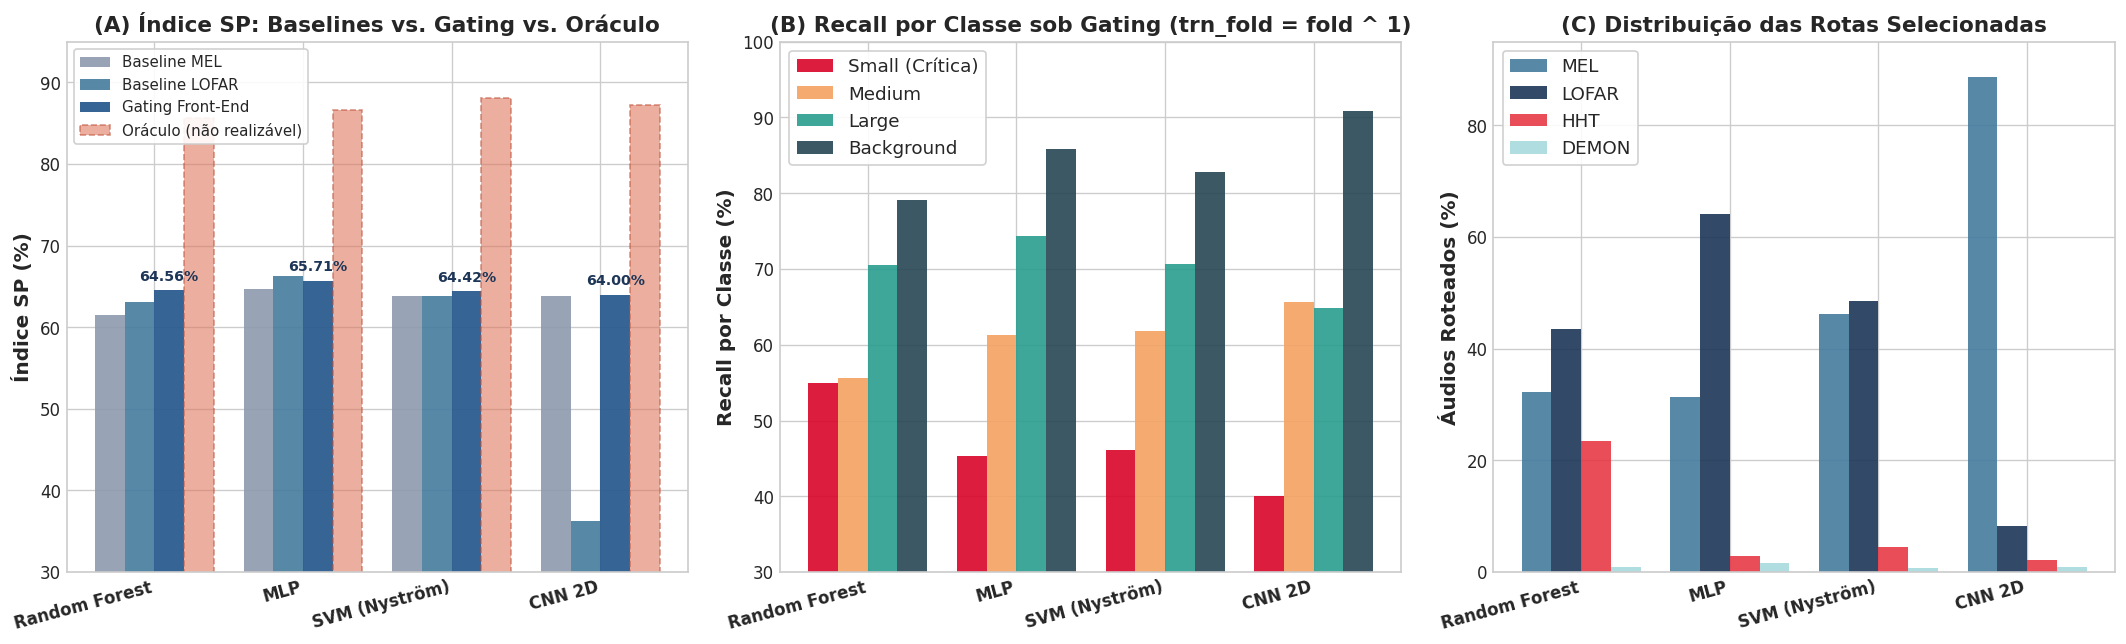

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Extração dinâmica a partir de df_master e models_data
classifiers = df_master['Classificador Downstream'].tolist()
sp_mel = [float(str(v).split()[0]) for v in df_master['Baseline MEL SP (%)']]
sp_lofar = [float(str(v).split()[0]) for v in df_master['Baseline LOFAR SP (%)']]
sp_gated = [float(str(v).split()[0]) for v in df_master['Gated SP (%)']]
sp_oracle = [float(str(v).split()[0]) for v in df_master['Oráculo SP (%)']]

x = np.arange(len(classifiers))
w = 0.20

axes[0].bar(x - 1.5*w, sp_mel, w, label='Baseline MEL', color='#8d99ae', alpha=0.9)
axes[0].bar(x - 0.5*w, sp_lofar, w, label='Baseline LOFAR', color='#457b9d', alpha=0.9)
axes[0].bar(x + 0.5*w, sp_gated, w, label='Gating Front-End', color='#2b5c8f', alpha=0.95)
axes[0].bar(x + 1.5*w, sp_oracle, w, label='Oráculo (não realizável)', color='#e07a5f', alpha=0.6, linestyle='--', edgecolor='#c0523b')

axes[0].set_xticks(x)
axes[0].set_xticklabels(classifiers, rotation=15, ha='right', fontweight='bold')
axes[0].set_ylabel('Índice SP (%)', fontweight='bold')
axes[0].set_title('(A) Índice SP: Baselines vs. Gating vs. Oráculo', fontweight='bold')
axes[0].set_ylim(30, 95)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9)

for i in range(len(classifiers)):
    axes[0].text(x[i] + 0.5*w, sp_gated[i] + 1.2, f"{sp_gated[i]:.2f}%", ha='center', fontsize=8.5, fontweight='bold', color='#1d3557')

# 2. Recall por Classe sob o Sistema Gated (lido dinamicamente de df_master)
rec_small = [float(str(v).replace('%', '')) for v in df_master['Recall SMALL (%)']]
rec_medium = [float(str(v).replace('%', '')) for v in df_master['Recall MEDIUM (%)']]
rec_large = [float(str(v).replace('%', '')) for v in df_master['Recall LARGE (%)']]
rec_bg = [float(str(v).replace('%', '')) for v in df_master['Recall BG (%)']]

w2 = 0.20
axes[1].bar(x - 1.5*w2, rec_small, w2, label='Small (Crítica)', color='#d90429', alpha=0.9)
axes[1].bar(x - 0.5*w2, rec_medium, w2, label='Medium', color='#f4a261', alpha=0.9)
axes[1].bar(x + 0.5*w2, rec_large, w2, label='Large', color='#2a9d8f', alpha=0.9)
axes[1].bar(x + 1.5*w2, rec_bg, w2, label='Background', color='#264653', alpha=0.9)

axes[1].set_xticks(x)
axes[1].set_xticklabels(classifiers, rotation=15, ha='right', fontweight='bold')
axes[1].set_ylabel('Recall por Classe (%)', fontweight='bold')
axes[1].set_title('(B) Recall por Classe sob Gating (trn_fold = fold ^ 1)', fontweight='bold')
axes[1].set_ylim(30, 100)
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left')

# 3. Distribuição Percentual de Rotas por Classificador (lida dinamicamente)
route_mel = [d['routes']['MEL'] / sum(d['routes'].values()) * 100 for _, _, d in models_data]
route_lofar = [d['routes']['LOFAR'] / sum(d['routes'].values()) * 100 for _, _, d in models_data]
route_hht = [d['routes']['HHT'] / sum(d['routes'].values()) * 100 for _, _, d in models_data]
route_demon = [d['routes']['DEMON'] / sum(d['routes'].values()) * 100 for _, _, d in models_data]

axes[2].bar(x - 1.5*w2, route_mel, w2, label='MEL', color='#457b9d', alpha=0.9)
axes[2].bar(x - 0.5*w2, route_lofar, w2, label='LOFAR', color='#1d3557', alpha=0.9)
axes[2].bar(x + 0.5*w2, route_hht, w2, label='HHT', color='#e63946', alpha=0.9)
axes[2].bar(x + 1.5*w2, route_demon, w2, label='DEMON', color='#a8dadc', alpha=0.9)

axes[2].set_xticks(x)
axes[2].set_xticklabels(classifiers, rotation=15, ha='right', fontweight='bold')
axes[2].set_ylabel('Áudios Roteados (%)', fontweight='bold')
axes[2].set_title('(C) Distribuição das Rotas Selecionadas', fontweight='bold')
axes[2].set_ylim(0, 95)
axes[2].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

### 3.2 Sensibilidade aos hiperparâmetros do roteador (18 variantes avaliadas no teste)

Repetimos o gate com `max_depth` ∈ {3, 5, None} × `min_samples_leaf` ∈ {1, 5} × peso do prior ∈ {0; 0,1; 0,3} (o restante idêntico). A configuração reportada é `(3, 5, 0,1)`.

| Gate | SP reportado (%) | Posição entre as 18 | Faixa das 18 (%) | Mediana (%) |
|---|---|---|---|---|
| Random Forest | 64,56 | 4ª de 18 | 62,97–64,74 | 64,32 |
| MLP | 65,71 | 1ª de 18 | 63,69–65,71 | 65,08 |
| SVM (Nyström) | 64,42 | 2ª de 18 | 60,37–64,45 | 63,65 |
| CNN 2D | 64,00 | 1ª de 18 | 59,99–64,00 | 63,13 |
| H-MoE especializado | 65,41 | 7ª de 18 | 64,17–65,79 | 65,29 |

A configuração reportada é a 4ª no RF, 1ª no MLP, 2ª no SVM, 1ª no CNN, 7ª no H-MoE entre as 18, e a faixa entre variantes (1,62 a 4,08 p.p.) é maior que as diferenças entre o gate e a melhor entrada isolada. Como a escolha foi feita olhando o teste, os SPs reportados do gate são otimistas; uma estimativa honesta exige escolher os hiperparâmetros por validação interna em `fold ^ 1` (*nested CV*).

A célula abaixo recalcula a grade (leva alguns minutos). Os valores da tabela acima foram calculados na geração do notebook; nas variantes sem limite de profundidade (`max_depth=None`) a célula pode diferir em ~0,1–0,15 p.p. conforme a versão do scikit-learn (desempates na construção das árvores). A configuração reportada (`max_depth=3`) reproduz exatamente os pickles.

In [7]:
grid_rows = []
for name, ex in [*[(f, G.homog(f)) for f in G.FAMS], ('H-MoE especializado', G.FIXED_HMOE)]:
    vals = {cfg: G.gate_folds(ex, depth=cfg[0], leaf=cfg[1], w_prior=cfg[2])[0].mean() for cfg in G.GRID}
    rep = vals[G.REPORTED_CFG]
    best_cfg = max(vals, key=vals.get)
    grid_rows.append({
        'Gate': name,
        'SP reportado (3, 5, 0.1)': round(rep, 2),
        'Posição (de 18)': 1 + sum(v > rep + 1e-9 for v in vals.values()),
        'Mín': round(min(vals.values()), 2), 'Mediana': round(float(np.median(list(vals.values()))), 2),
        'Máx': round(max(vals.values()), 2), 'Config. do máximo (depth, leaf, w)': best_cfg,
    })
display(pd.DataFrame(grid_rows))

,Gate,"SP reportado (3, 5, 0.1)",Posição (de 18),Mín,Mediana,Máx,"Config. do máximo (depth, leaf, w)"
0,RF,64.56,4,62.98,64.32,64.74,"(3, 1, 0.1)"
1,MLP,65.71,1,63.56,65.08,65.71,"(3, 5, 0.1)"
2,SVM,64.42,2,60.34,63.66,64.45,"(3, 1, 0.3)"
3,CNN,64.00,1,59.96,63.13,64.00,"(3, 5, 0.1)"
4,H-MoE especializado,65.41,7,64.17,65.31,65.79,"(3, 5, 0.3)"


## 4. Arquitetura Heterogênea: Gating Front-End com Especialistas Distintos (H-MoE)

Na Seção 3, a mesma família de classificador foi usada nos 4 ramos. Os especialistas isolados de maior SP por representação são:
* **LOFAR:** o especialista isolado de maior SP entre os 16 é o **MLP-LOFAR** (**66,24 ± 1,78**); o MLP-LOFAR vem do pipeline oficial;
* **HHT:** o **Random Forest** alcança **60,64 ± 1,91**, com 52,2% de recall em *Small* (MLP-HHT: 26,9%; SVM-HHT: 41,7%);
* **MEL:** o **Random Forest** tem o maior recall de *Small* entre os MEL (58,1%), mas SP 61,45 ± 1,90, abaixo de MLP-MEL (64,74 ± 2,05) e SVM-MEL (63,78 ± 1,14).

Abaixo avaliamos o sistema **H-MoE (Heterogeneous Mixture of Experts)** de duas formas:
* **Automático:** o especialista de cada representação é escolhido entre RF, MLP e SVM pelo SP no fold disjunto (*Nested CV* em `trn_fold = fold ^ 1`);
* **Especializado fixo** (`MEL:RF, LOFAR:MLP, HHT:RF, DEMON:MLP`): este mapa foi escolhido pelo autor **depois** de ver os resultados isolados de teste, logo não é uma estimativa independente.

In [8]:
# Carregar resultados do H-MoE Heterogêneo (treinado estritamente em trn_fold = fold ^ 1)
hmoe_paths = [
    'data/iara_processed/results_heterogeneous_gating.pkl',
    '../data/iara_processed/results_heterogeneous_gating.pkl'
]
hmoe_path = next((p for p in hmoe_paths if os.path.exists(p)), None)
with open(hmoe_path, 'rb') as f:
    hmoe_data = pickle.load(f)
print("=== TABELA COMPARATIVA (LEAK-FREE trn_fold = fold ^ 1): H-MoE VS. GATING HOMOGÊNEO ===")
print("Linha 6 (Super-Oráculo): usa o rótulo para escolher entre 16 especialistas -> não realizável.")
display(hmoe_data['df'])
print("\nDescoberta Automática de Especialistas por Representação (Nested CV em trn_fold = fold ^ 1):")
for r, models in hmoe_data['selected_models_per_fold'].items():
    counts_str = ", ".join([f"{m} ({c}/10 folds)" for m, c in Counter(models).most_common()])
    print(f"  {r.upper()}: {counts_str}")

# F-test 5x2cv contra o melhor especialista isolado (MLP-LOFAR), com SP por fold
mlp_lofar = G.single_folds('MLP', 'lofar')[0]
hfix = G.gate_folds(G.FIXED_HMOE)[0]
hauto = G.hmoe_auto_folds()
assert abs(hfix.mean() - sp_of(hmoe_data['df'].iloc[4]['SP (%)'])) < 0.006
assert abs(hauto.mean() - sp_of(hmoe_data['df'].iloc[3]['SP (%)'])) < 0.006
tests = []
for nome, a in [('H-MoE Automático', hauto), ('H-MoE Especializado', hfix),
                ('Gated RF', gate_folds['RF']), ('Gated MLP', gate_folds['MLP']),
                ('Gated SVM', gate_folds['SVM']), ('Gated CNN', gate_folds['CNN'])]:
    F, p = G.f_test_5x2(a, mlp_lofar)
    tests.append({'Sistema': nome, 'SP (%)': f"{a.mean():.2f} ± {a.std():.2f}",
                  'Δ vs MLP-LOFAR (p.p.)': f"{a.mean() - mlp_lofar.mean():+.2f}", 'F': round(F, 2), 'p': round(p, 3)})
print(f"\nF-test 5x2cv contra o MLP-LOFAR isolado ({mlp_lofar.mean():.2f} ± {mlp_lofar.std():.2f}):")
display(pd.DataFrame(tests))
print(f"Referência — MLP LOFAR na Tabela 7 do artigo: SP {R.ARTICLE_TABLE7[('MLP', 'LOFAR')]['SP'][0]:.2f} ± {R.ARTICLE_TABLE7[('MLP', 'LOFAR')]['SP'][1]:.2f}")

# Super-Oráculo vs. referências de acaso
sup = G.oracle(G.ALL16)
print(f"\nSuper-Oráculo (16 especialistas): SP {sup['sp'].mean():.2f} ± {sup['sp'].std():.2f}")
print(f"  esperado se os erros dos 16 fossem independentes: SP {sup['sp_exp']:.3f}")
print(f"  oráculo de 16 preditores uniformemente aleatórios: SP {G.random_oracle_sp(16):.2f}")
print(f"  oráculo de 4 preditores uniformemente aleatórios:  SP {G.random_oracle_sp(4):.2f}")

=== TABELA COMPARATIVA (LEAK-FREE trn_fold = fold ^ 1): H-MoE VS. GATING HOMOGÊNEO ===
Linha 6 (Super-Oráculo): usa o rótulo para escolher entre 16 especialistas -> não realizável.


,Arquitetura,SP (%),Bal Acc (%),Acc (%),Recall SMALL (%),Recall MEDIUM (%),Recall LARGE (%),Recall BG (%)
0,1. Baseline MEL Isolado (RF),61.45 ± 1.90,61.55 ± 1.89,61.83 ± 1.74,58.1%,58.7%,66.7%,62.7%
1,2. Baseline LOFAR Isolado (MLP),66.24 ± 1.78,67.22 ± 1.65,65.51 ± 1.72,46.3%,61.5%,74.7%,86.3%
2,"3. Gated RF Homogêneo (MEL, LOFAR, HHT, DEMON ...",64.56 ± 1.70,65.03 ± 1.62,64.01 ± 1.63,54.9%,55.6%,70.5%,79.1%
3,4. H-MoE Automático (Nested CV Model Selection),64.55 ± 1.70,65.60 ± 1.63,63.71 ± 1.61,44.4%,60.5%,72.1%,85.5%
4,"5. H-MoE Especializado (MEL:RF, LOFAR:MLP, HHT...",65.41 ± 2.00,66.10 ± 2.02,64.55 ± 2.08,50.7%,59.4%,71.1%,83.2%
5,6. Super-Oráculo Teórico (16 Especialistas: 4 ...,97.70 ± 0.75,97.70 ± 0.74,97.48 ± 0.68,97.5%,96.4%,97.1%,99.7%



Descoberta Automática de Especialistas por Representação (Nested CV em trn_fold = fold ^ 1):
  MEL: MLP (5/10 folds), SVM (5/10 folds)
  LOFAR: MLP (9/10 folds), SVM (1/10 folds)
  HHT: RF (9/10 folds), MLP (1/10 folds)
  DEMON: MLP (10/10 folds)



F-test 5x2cv contra o MLP-LOFAR isolado (66.24 ± 1.78):


,Sistema,SP (%),Δ vs MLP-LOFAR (p.p.),F,p
0,H-MoE Automático,64.55 ± 1.70,-1.69,1.11,0.484
1,H-MoE Especializado,65.41 ± 2.00,-0.83,0.76,0.667
2,Gated RF,64.56 ± 1.70,-1.68,0.93,0.568
3,Gated MLP,65.71 ± 2.29,-0.54,0.64,0.741
4,Gated SVM,64.42 ± 1.93,-1.82,1.01,0.531
5,Gated CNN,64.00 ± 2.44,-2.24,3.05,0.115


Referência — MLP LOFAR na Tabela 7 do artigo: SP 66.51 ± 1.39

Super-Oráculo (16 especialistas): SP 97.70 ± 0.75
  esperado se os erros dos 16 fossem independentes: SP 99.996
  oráculo de 16 preditores uniformemente aleatórios: SP 99.00
  oráculo de 4 preditores uniformemente aleatórios:  SP 68.36


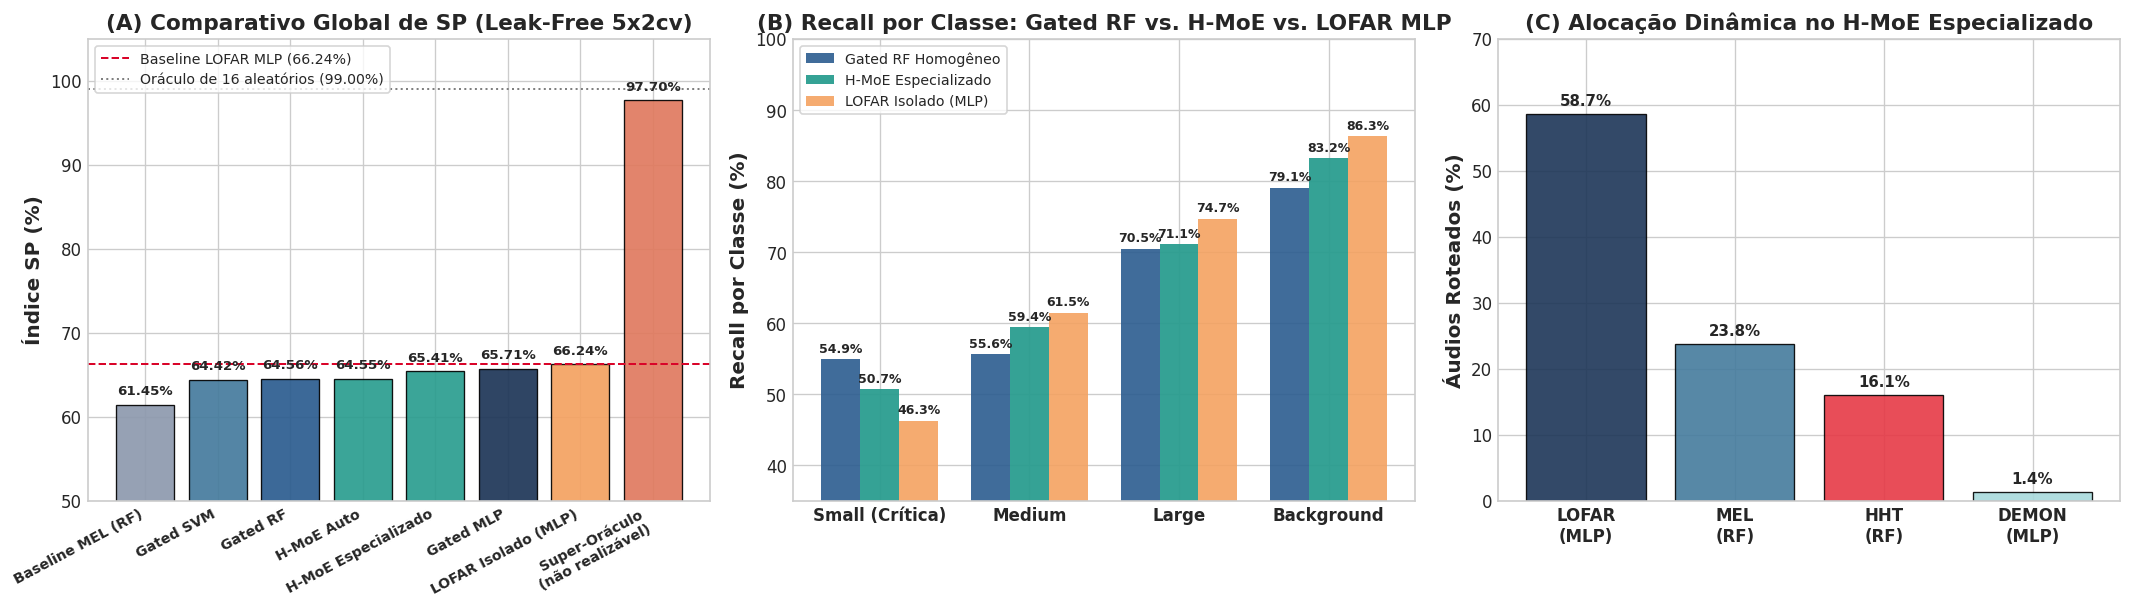

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

df_h = hmoe_data['df']
sp_mel_rf = float(str(df_h.iloc[0]['SP (%)']).split()[0])
sp_lof_mlp = float(str(df_h.iloc[1]['SP (%)']).split()[0])
sp_gated_rf = float(str(df_h.iloc[2]['SP (%)']).split()[0])
sp_hmoe_auto = float(str(df_h.iloc[3]['SP (%)']).split()[0])
sp_hmoe_fix = float(str(df_h.iloc[4]['SP (%)']).split()[0])
sp_super_ora = float(str(df_h.iloc[5]['SP (%)']).split()[0])
sp_gated_svm = float(str(res_svm['df'].iloc[4]['SP (%)']).split()[0])
sp_gated_mlp = float(str(res_all['MLP']['df'].iloc[4]['SP (%)']).split()[0])

# 1. Índice SP (Leak-Free)
archs = [
    'Baseline MEL (RF)', 'Gated SVM', 'Gated RF', 'H-MoE Auto',
    'H-MoE Especializado', 'Gated MLP', 'LOFAR Isolado (MLP)', 'Super-Oráculo\n(não realizável)'
]
sps = [sp_mel_rf, sp_gated_svm, sp_gated_rf, sp_hmoe_auto, sp_hmoe_fix, sp_gated_mlp, sp_lof_mlp, sp_super_ora]
colors = ['#8d99ae', '#457b9d', '#2b5c8f', '#2a9d8f', '#2a9d8f', '#1d3557', '#f4a261', '#e07a5f']

bars = axes[0].bar(range(len(archs)), sps, color=colors, alpha=0.92, edgecolor='black', linewidth=0.8)
axes[0].set_xticks(range(len(archs)))
axes[0].set_xticklabels(archs, rotation=28, ha='right', fontweight='bold', fontsize=8.5)
axes[0].set_ylabel('Índice SP (%)', fontweight='bold')
axes[0].set_title('(A) Comparativo Global de SP (Leak-Free 5x2cv)', fontweight='bold')
axes[0].set_ylim(50, 105)
axes[0].axhline(sp_lof_mlp, color='#d90429', linestyle='--', linewidth=1.2, label=f'Baseline LOFAR MLP ({sp_lof_mlp:.2f}%)')
axes[0].axhline(G.random_oracle_sp(16), color='gray', linestyle=':', linewidth=1.2, label=f'Oráculo de 16 aleatórios ({G.random_oracle_sp(16):.2f}%)')
axes[0].legend(loc='upper left', frameon=True, facecolor='white', fontsize=8.5)
for bar, s in zip(bars, sps):
    axes[0].text(bar.get_x() + bar.get_width()/2, s + 1.2, f'{s:.2f}%', ha='center', fontsize=8, fontweight='bold')

# 2. Recall por Classe: Gated RF vs H-MoE Especializado vs LOFAR MLP
classes = ['Small (Crítica)', 'Medium', 'Large', 'Background']
rec_cols = ['Recall SMALL (%)', 'Recall MEDIUM (%)', 'Recall LARGE (%)', 'Recall BG (%)']
rec_rf = [float(str(df_h.iloc[2][c]).replace('%', '')) for c in rec_cols]
rec_hmoe = [float(str(df_h.iloc[4][c]).replace('%', '')) for c in rec_cols]
rec_lof = [float(str(df_h.iloc[1][c]).replace('%', '')) for c in rec_cols]
x = np.arange(len(classes))
w = 0.26
axes[1].bar(x - w, rec_rf, w, label='Gated RF Homogêneo', color='#2b5c8f', alpha=0.9)
axes[1].bar(x, rec_hmoe, w, label='H-MoE Especializado', color='#2a9d8f', alpha=0.95)
axes[1].bar(x + w, rec_lof, w, label='LOFAR Isolado (MLP)', color='#f4a261', alpha=0.9)
axes[1].set_xticks(x)
axes[1].set_xticklabels(classes, fontweight='bold')
axes[1].set_ylabel('Recall por Classe (%)', fontweight='bold')
axes[1].set_title('(B) Recall por Classe: Gated RF vs. H-MoE vs. LOFAR MLP', fontweight='bold')
axes[1].set_ylim(35, 100)
axes[1].legend(loc='upper left', frameon=True, facecolor='white', fontsize=8.5)
for i in range(len(classes)):
    axes[1].text(x[i] - w, rec_rf[i] + 1.0, f'{rec_rf[i]:.1f}%', ha='center', fontsize=7.5, fontweight='bold')
    axes[1].text(x[i], rec_hmoe[i] + 1.0, f'{rec_hmoe[i]:.1f}%', ha='center', fontsize=7.5, fontweight='bold')
    axes[1].text(x[i] + w, rec_lof[i] + 1.0, f'{rec_lof[i]:.1f}%', ha='center', fontsize=7.5, fontweight='bold')

# 3. Distribuição das Rotas e Modelos no H-MoE Especializado (lida dinamicamente)
rf_cnt = hmoe_data['routes_fixed']
tot_rf_cnt = sum(rf_cnt.values())
route_keys = ['LOFAR:MLP', 'MEL:RF', 'HHT:RF', 'DEMON:MLP']
routes_labels = ['LOFAR\n(MLP)', 'MEL\n(RF)', 'HHT\n(RF)', 'DEMON\n(MLP)']
pcts = [rf_cnt[k] / tot_rf_cnt * 100 for k in route_keys]
pie_colors = ['#1d3557', '#457b9d', '#e63946', '#a8dadc']
axes[2].bar(range(len(routes_labels)), pcts, color=pie_colors, alpha=0.9, edgecolor='black', linewidth=0.8)
axes[2].set_xticks(range(len(routes_labels)))
axes[2].set_xticklabels(routes_labels, fontweight='bold')
axes[2].set_ylabel('Áudios Roteados (%)', fontweight='bold')
axes[2].set_title('(C) Alocação Dinâmica no H-MoE Especializado', fontweight='bold')
axes[2].set_ylim(0, 70)
for i, p in enumerate(pcts):
    axes[2].text(i, p + 1.2, f'{p:.1f}%', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Conclusões e Recomendações

### Principais Conclusões (Protocolo $5\times2\text{cv}$ com roteador treinado em `fold ^ 1`):

1. **Por que o treino estritamente disjunto (`trn_fold = fold ^ 1`) é obrigatório em $5\times2\text{cv}$:**
   * Cada fold de teste tem 639 das 1.706 gravações do UO, e o split é por gravação (`ID`), não por navio. As 7 meta-características (`crest_factor`, `spectral_flatness`, `mod_index`, `flux_std`, `high_low_ratio`, `rms_db`, `zcr`) são extraídas dos primeiros $10\text{ s}$ de cada arquivo; treinar o roteador nos "outros 9 folds" vazaria $99,6\%$ dos arquivos de teste, presentes nas outras 4 repetições.
   * Restringindo o roteador e a seleção *Nested CV* ao fold complementar da mesma repetição (`trn_fold = fold ^ 1`, 0% de sobreposição de arquivos), eliminamos a memorização por arquivo.

2. **Gate homogêneo: equivalente à melhor entrada isolada de cada família (nenhum ganho demonstrado).**
   * **Gated Random Forest (64,56 ± 1,70):** contra o RF-LOFAR isolado (63,12 ± 1,73), F-test 5×2cv p = 0,46. O roteador distribui os contatos entre LOFAR (43,5%), MEL (32,3%) e HHT (23,4%), e o recall de `SMALL` fica em 54,9% (RF-LOFAR isolado: 48,7%).
   * **Gated SVM (64,42 ± 1,93):** contra o SVM-LOFAR isolado (63,83 ± 1,91), p = 0,36; rotas LOFAR 48,5% e MEL 46,2%.
   * **Gated MLP (65,71 ± 2,29):** contra o MLP-LOFAR isolado (66,24 ± 1,78), p = 0,74.
   * **Gated CNN 2D (64,00 ± 2,44):** contra a CNN-MEL isolada (63,80 ± 2,23), p = 0,63. O gate manda 88,7% das rotas ao MEL; os especialistas CNN-LOFAR/HHT/DEMON ad hoc estão colapsados, então não cabe anunciar ganho sobre eles.
   * Além disso, a configuração do roteador foi escolhida no teste (Seção 3.2), o que torna esses SPs otimistas.

3. **H-MoE e o melhor especialista isolado (MLP-LOFAR, 66,24 ± 1,78):**
   * O **H-MoE Especializado (65,41 ± 2,00)** não difere significativamente do MLP-LOFAR isolado (F = 0,76, p = 0,67) nem do Gated RF homogêneo (F = 4,07, p = 0,07). Seu recall de `SMALL` é 50,7% contra 46,3% do MLP-LOFAR.
   * O **H-MoE Automático (64,55 ± 1,70)** não difere significativamente do MLP-LOFAR (F = 1,11, p = 0,48).
   * O **Gated MLP** também não difere significativamente do MLP-LOFAR (p = 0,74).
   * *Hipótese (não testada):* quando um especialista domina (`LOFAR:MLP`), 7 descritores globais de uma única janela de $10\text{ s}$ podem não ter informação suficiente para identificar os poucos áudios em que outro especialista acerta e ele erra; desviar áudios para especialistas de SP menor tende a gerar trocas líquidas nulas ou negativas.

4. **Super-Oráculo (97,70 ± 0,75) não é teto alcançável nem evidência de complementaridade.**
   * O Super-Oráculo escolhe, com o rótulo verdadeiro, o especialista que acerta: não é um sistema realizável.
   * O oráculo de **16 preditores uniformemente aleatórios** já teria SP de 99,00%, e o esperado se os erros dos 16 especialistas fossem independentes é 99,996%. O valor observado fica **abaixo** dessas duas referências: os erros dos especialistas são correlacionados, e o número de 16 tentativas por áudio, sozinho, já explica um oráculo próximo de 100%.
   * O que este notebook mostra é que, com os dados atuais, **nenhum** roteador baseado nas 7 meta-features supera de forma estatisticamente significativa o melhor especialista isolado. Para avançar: (i) escolher os hiperparâmetros do roteador por validação interna; (ii) usar especialistas homogêneos e não colapsados; (iii) testar descritores mais informativos para o roteamento.